## Importo posibles librerías

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

## ANÁLISIS 5 - Análisis del rendimiento según la preparación previa de los exámenes

La variable "test preparation course" permite comparar a los estudiantes que han completado un curso de preparación con aquellos que no lo han hecho, respecto a las notas en cada competencia.

Esto permite investigar descriptivamente si la preparación previa está asociada con un mejor rendimiento.

In [2]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

Realizo el gráfico del rendimiento académico según la preparación previa para los exámenes

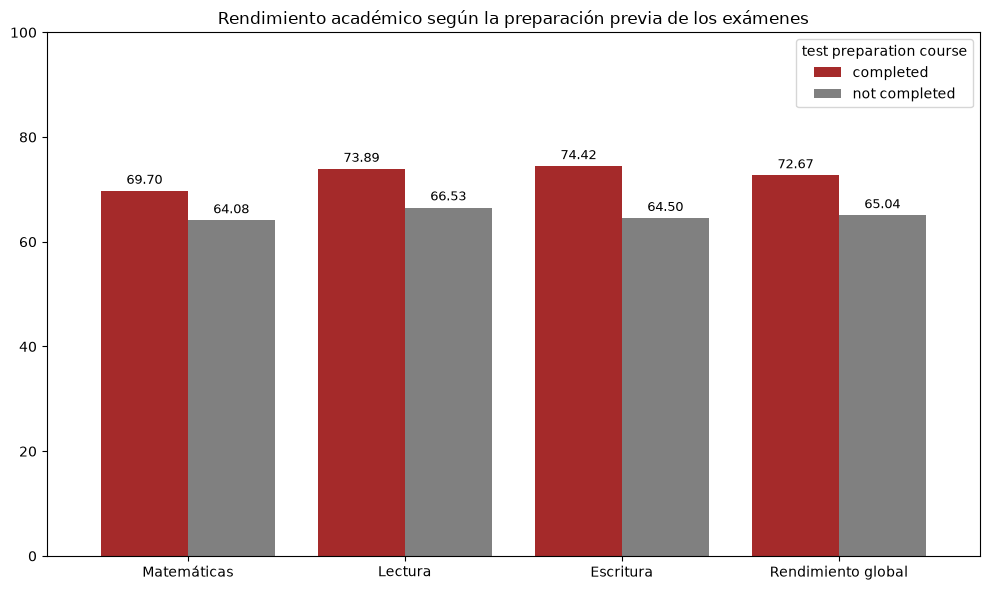

In [3]:
rendimiento_previo = sp.groupby("test_preparation_course")[["math_score", "reading_score", "writing_score", "global_score"]].mean()

rendimiento_previo = rendimiento_previo.T #trasponer los datos para poder sacar el gráfico que quiero

rend = rendimiento_previo.plot(kind="bar", figsize=(10, 6), width=0.8, color=["brown", "grey"])

plt.title("Rendimiento académico según la preparación previa de los exámenes")
plt.xticks(ticks=range(4), labels=["Matemáticas", "Lectura", "Escritura", "Rendimiento global"], rotation=0)

for container in rend.containers:
    rend.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.ylim(0, 100)
plt.legend(title="test preparation course")

plt.tight_layout()

plt.savefig("../img/Grafico_5_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

En el gráfico se observan claras diferencias en todas las competencias entre haber realizado el curso preparatorio y no haberlo realizado.
Todo apunta a que sí sean diferencias estadísticamente significativas. Vamos a comprobarlo:

In [4]:
variables = ["math_score", "reading_score", "writing_score", "global_score"]

for variable in variables:

    completado = sp[sp["test_preparation_course"] == "completed"][variable]
    no_completado = sp[sp["test_preparation_course"] == "not completed"][variable]

    t, p = ttest_ind(completado, no_completado, equal_var=False)

    print("\n", variable)
    print("Estadístico t:", round(t, 4))
    print("p-valor:", round(p, 4))

    if p < 0.05:
        print("Existe una diferencia estadísticamente significativa")
    else:
        print("No existe una diferencia estadísticamente significativa")


 math_score
Estadístico t: 5.787
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 reading_score
Estadístico t: 8.0041
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 writing_score
Estadístico t: 10.7525
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 global_score
Estadístico t: 8.5947
p-valor: 0.0
Existe una diferencia estadísticamente significativa


Los resultados confirman que las diferencias son estadísticamente significativas. Vemos que la media de los estudiantes que han completado el curso preparatorio es significativamente mejor que la media de los que no lo han hecho.

Por tanto, esta variable tambien es un factor importante en el rendimiento de los exámenes.